Mounting gd and exploring dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base_path = "/content/CASIA"

for root, dirs, files in os.walk(base_path):
    print(root)
    print("Folders:", len(dirs))
    print("Files:", len(files))
    print("-"*40)

In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'Computer Science and Engineering(Artificial Intelligence and Machine Learining)_copy.pdf', 'S1 notes', '25GCL102SM_DATA_SHEET.pdf', 'Document from Nirenjana.pdf', 'Iris.csv', 'Classroom', 'housing.zip', 'Questionnaire PSO-CSE(AI&ML).docx', 'image.zip', 'AIML_CUSAT']


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/image.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/CASIA')

print("Extraction complete!")

Extraction complete!


In [ ]:
import os

for root, dirs, files in os.walk('/content/CASIA'):
    print(root)
    print("Folders:", len(dirs))
    print("Files:", len(files))
    print("-"*50)

/content/CASIA
Folders: 1
Files: 0
--------------------------------------------------
/content/CASIA/CASIA2
Folders: 3
Files: 0
--------------------------------------------------
/content/CASIA/CASIA2/CASIA 2 Groundtruth
Folders: 0
Files: 5123
--------------------------------------------------
/content/CASIA/CASIA2/Tp
Folders: 0
Files: 5125
--------------------------------------------------
/content/CASIA/CASIA2/Au
Folders: 0
Files: 7492
--------------------------------------------------


In [ ]:
import os

for root, dirs, files in os.walk('/content/CASIA'):
    if len(files) > 0:
        print(root)
        print("Sample files:", files[:5])
        print()

/content/CASIA/CASIA2/CASIA 2 Groundtruth
Sample files: ['Tp_S_NNN_S_N_nat20025_nat20025_01529_gt.png', 'Tp_S_NNN_S_N_cha10172_cha10172_12284_gt.png', 'Tp_D_NNN_M_B_sec00036_nat00035_20123_gt.png', 'Tp_S_CNN_M_N_art00069_art00069_10853_gt.png', 'Tp_S_NRN_M_N_cha00055_cha00055_11727_gt.png']

/content/CASIA/CASIA2/Tp
Sample files: ['Tp_S_CNN_S_N_art00080_art00080_01247.tif', 'Tp_S_NRN_S_B_art00039_art00039_01415.tif', 'Tp_D_NRN_M_B_nat10128_nat00097_11542.jpg', 'Tp_D_NRN_S_N_arc00013_sec00045_11700.jpg', 'Tp_D_NRN_S_N_arc00090_art00010_00013.tif']

/content/CASIA/CASIA2/Au
Sample files: ['Au_ind_30036.jpg', 'Au_cha_30560.jpg', 'Au_cha_30636.jpg', 'Au_sec_30279.jpg', 'Au_art_30631.jpg']



In [ ]:
AU_PATH = "/content/CASIA/CASIA2/Au"
TP_PATH = "/content/CASIA/CASIA2/Tp"
MASK_PATH = "/content/CASIA/CASIA2/CASIA 2 Groundtruth"

print("Authentic Images:", len(os.listdir(AU_PATH)))
print("Tampered Images:", len(os.listdir(TP_PATH)))
print("Masks:", len(os.listdir(MASK_PATH)))

Authentic Images: 7492
Tampered Images: 5125
Masks: 5123


catagory

In [ ]:
import os
from collections import Counter

folder = "/content/CASIA/CASIA2/Au"

categories = []

for filename in os.listdir(folder):
    parts = filename.split("_")

    if len(parts) >= 2:
        categories.append(parts[1])

Counter(categories)

Counter({'ind': 346,
         'cha': 980,
         'sec': 953,
         'art': 913,
         'ani': 1094,
         'nat': 1008,
         'pla': 976,
         'arc': 1075,
         'txt': 146})

In [ ]:
import os
from collections import Counter

folder = "/content/CASIA/CASIA2/Tp"

categories = []

for filename in os.listdir(folder):

    parts = filename.split("_")

    for part in parts:
        if len(part) >= 3 and part[:3].isalpha():
            categories.append(part[:3])

Counter(categories)

Counter({'CNN': 567,
         'art': 1250,
         'NRN': 1648,
         'nat': 1602,
         'arc': 1145,
         'sec': 1075,
         'CRN': 532,
         'ind': 1011,
         'NNN': 1843,
         'cha': 1415,
         'CND': 42,
         'CRD': 83,
         'pla': 1036,
         'ani': 1302,
         'NRD': 211,
         'NND': 196,
         'txt': 410,
         'Thu': 1,
         'CnN': 1,
         'lis': 1})

The CASIA 2.0 dataset contains images from multiple categories including animals, architecture, nature, plants, scenes, text, indoor environments, and artificial objects.

VISUALISE SAMPLE IMAGES

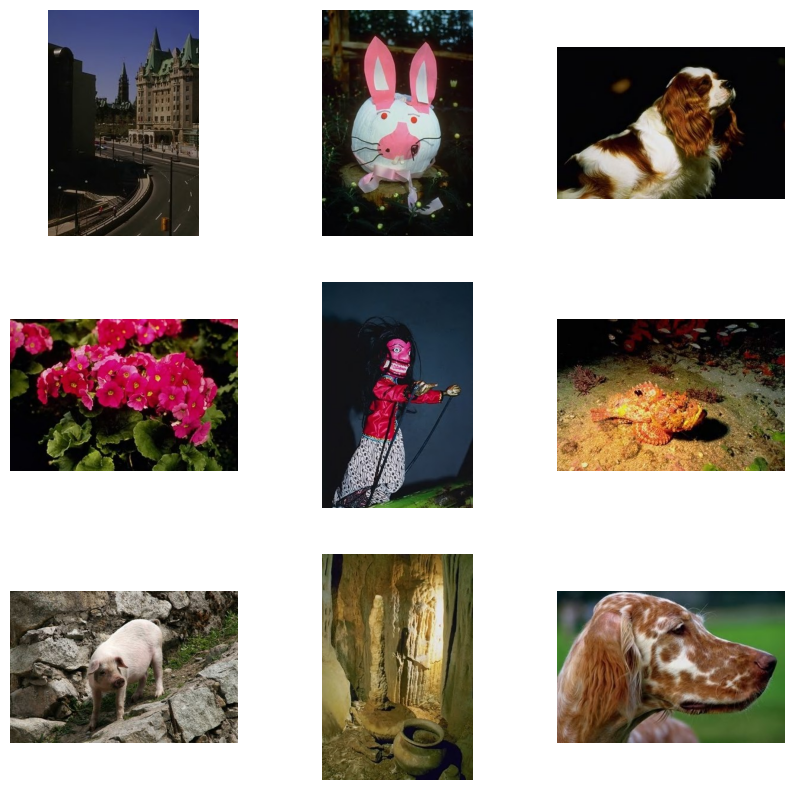

In [ ]:
import cv2
import matplotlib.pyplot as plt
import random

sample_files = random.sample(os.listdir(AU_PATH), 9)

plt.figure(figsize=(10,10))

for i, file in enumerate(sample_files):
    img = cv2.imread(os.path.join(AU_PATH, file))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(3,3,i+1)
    plt.imshow(img)
    plt.axis("off")

plt.show()

VISUALISING AUTHENTIC IMAGES

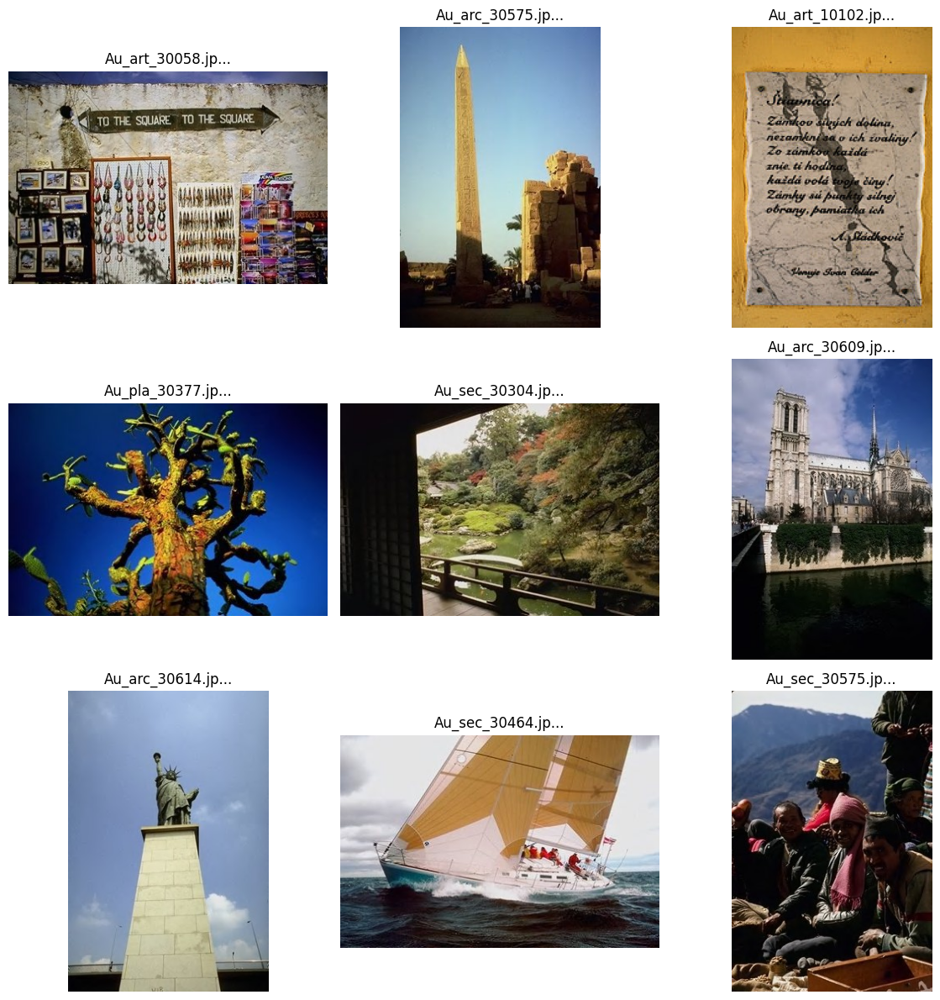

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

AU_PATH = "/content/CASIA/CASIA2/Au"

# Pick 9 random authentic images
sample_files = random.sample(os.listdir(AU_PATH), 9)

plt.figure(figsize=(12, 12))

for i, file in enumerate(sample_files):
    img_path = os.path.join(AU_PATH, file)

    img = cv2.imread(img_path)

    # Convert BGR to RGB for matplotlib
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(file[:15] + "...")
    plt.axis("off")

plt.tight_layout()
plt.show()

visualize tampered images

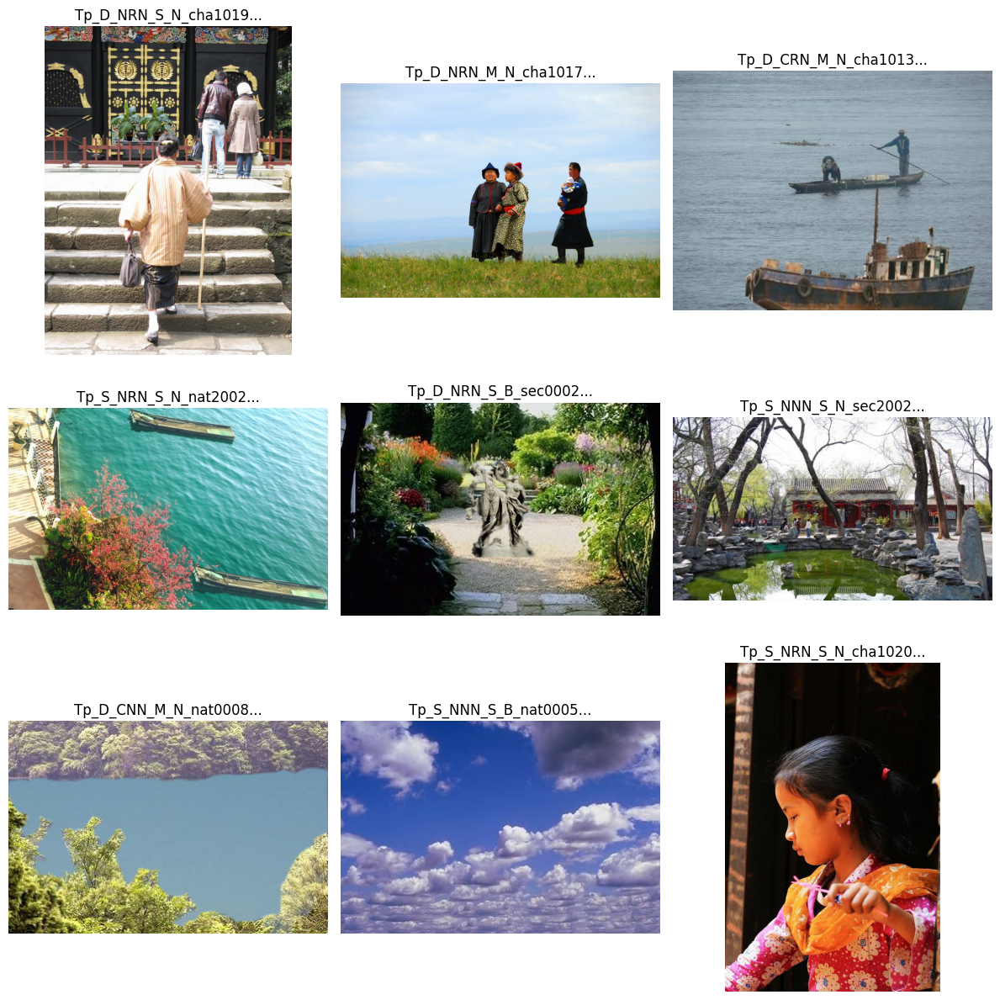

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

TP_PATH = "/content/CASIA/CASIA2/Tp"

# Select 9 random tampered images
sample_files = random.sample(os.listdir(TP_PATH), 9)

plt.figure(figsize=(12, 12))

for i, file in enumerate(sample_files):
    img_path = os.path.join(TP_PATH, file)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(file[:20] + "...")
    plt.axis("off")

plt.tight_layout()
plt.show()

authentic +tampered + Ground Truth Mask

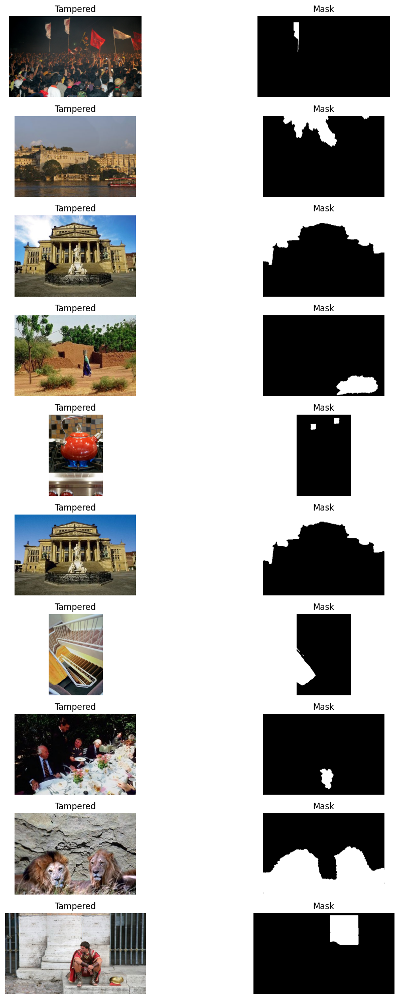

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

pairs = []

for file in os.listdir(TP_PATH):
    mask = file.rsplit(".", 1)[0] + "_gt.png"
    if os.path.exists(os.path.join(MASK_PATH, mask)):
        pairs.append((file, mask))

samples = random.sample(pairs, 10)

plt.figure(figsize=(12,20))

for i, (tp_file, mask_file) in enumerate(samples):

    tp_img = cv2.cvtColor(
        cv2.imread(os.path.join(TP_PATH, tp_file)),
        cv2.COLOR_BGR2RGB
    )

    mask_img = cv2.imread(
        os.path.join(MASK_PATH, mask_file),
        cv2.IMREAD_GRAYSCALE
    )

    plt.subplot(10,2,2*i+1)
    plt.imshow(tp_img)
    plt.title("Tampered")
    plt.axis("off")

    plt.subplot(10,2,2*i+2)
    plt.imshow(mask_img, cmap="gray")
    plt.title("Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

ELA (ERROR LEVEL ANALYSIS)

In [ ]:
from PIL import Image, ImageChops, ImageEnhance

def convert_to_ela_image(path, quality=90):

    original = Image.open(path).convert("RGB")

    temp_filename = "temp.jpg"

    original.save(
        temp_filename,
        "JPEG",
        quality=quality
    )

    compressed = Image.open(temp_filename)

    ela_image = ImageChops.difference(
        original,
        compressed
    )

    extrema = ela_image.getextrema()

    max_diff = max(
        [pix[1] for pix in extrema]
    )

    scale = 255.0 / max_diff if max_diff != 0 else 1

    ela_image = ImageEnhance.Brightness(
        ela_image
    ).enhance(scale)

    return ela_image

Test ELA on a Tampered Image

In [ ]:
import random
import os
import matplotlib.pyplot as plt

sample_file = random.choice(
    os.listdir(TP_PATH)
)

sample_path = os.path.join(
    TP_PATH,
    sample_file
)

ela_image = convert_to_ela_image(
    sample_path
)

visualize

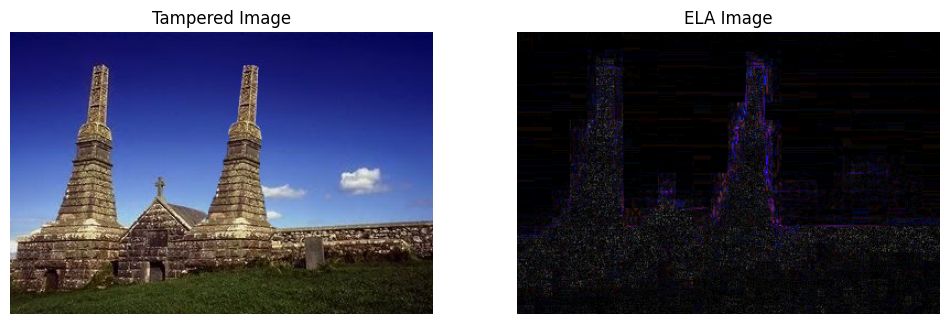

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(Image.open(sample_path))
plt.title("Tampered Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(ela_image)
plt.title("ELA Image")
plt.axis("off")

plt.show()

Authentic + ELA

In [ ]:
from PIL import Image, ImageChops, ImageEnhance
import matplotlib.pyplot as plt
import os
import random

In [ ]:
def convert_to_ela(image_path, quality=90):

    temp_filename = "temp.jpg"

    image = Image.open(image_path).convert("RGB")

    image.save(temp_filename, "JPEG", quality=quality)

    compressed = Image.open(temp_filename)

    ela_image = ImageChops.difference(image, compressed)

    extrema = ela_image.getextrema()

    max_diff = max([ex[1] for ex in extrema])

    if max_diff == 0:
        max_diff = 1

    scale = 255.0 / max_diff

    ela_image = ImageEnhance.Brightness(ela_image).enhance(scale)

    return ela_image

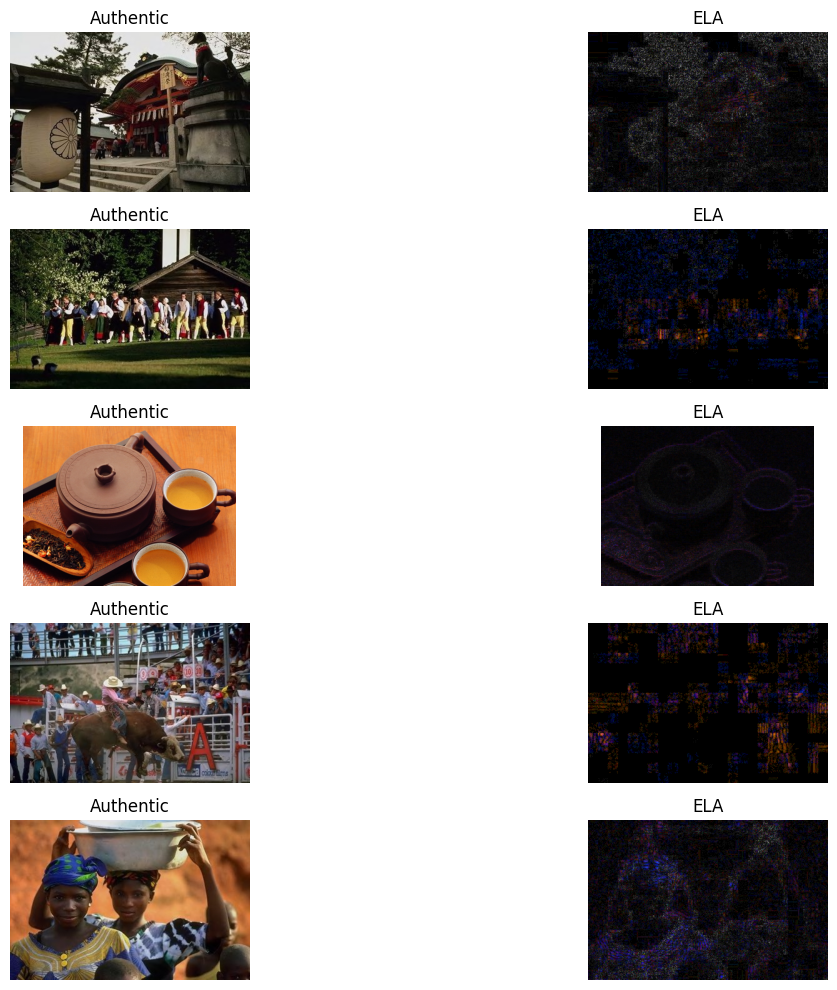

In [ ]:
au_folder = "/content/CASIA/CASIA2/Au"

au_images = random.sample(os.listdir(au_folder), 5)

plt.figure(figsize=(15,10))

for i, img_name in enumerate(au_images):

    img_path = os.path.join(au_folder, img_name)

    original = Image.open(img_path)
    ela = convert_to_ela(img_path)

    plt.subplot(5,2,2*i+1)
    plt.imshow(original)
    plt.title("Authentic")
    plt.axis("off")

    plt.subplot(5,2,2*i+2)
    plt.imshow(ela)
    plt.title("ELA")
    plt.axis("off")

plt.tight_layout()
plt.show()

Tampered + ELA

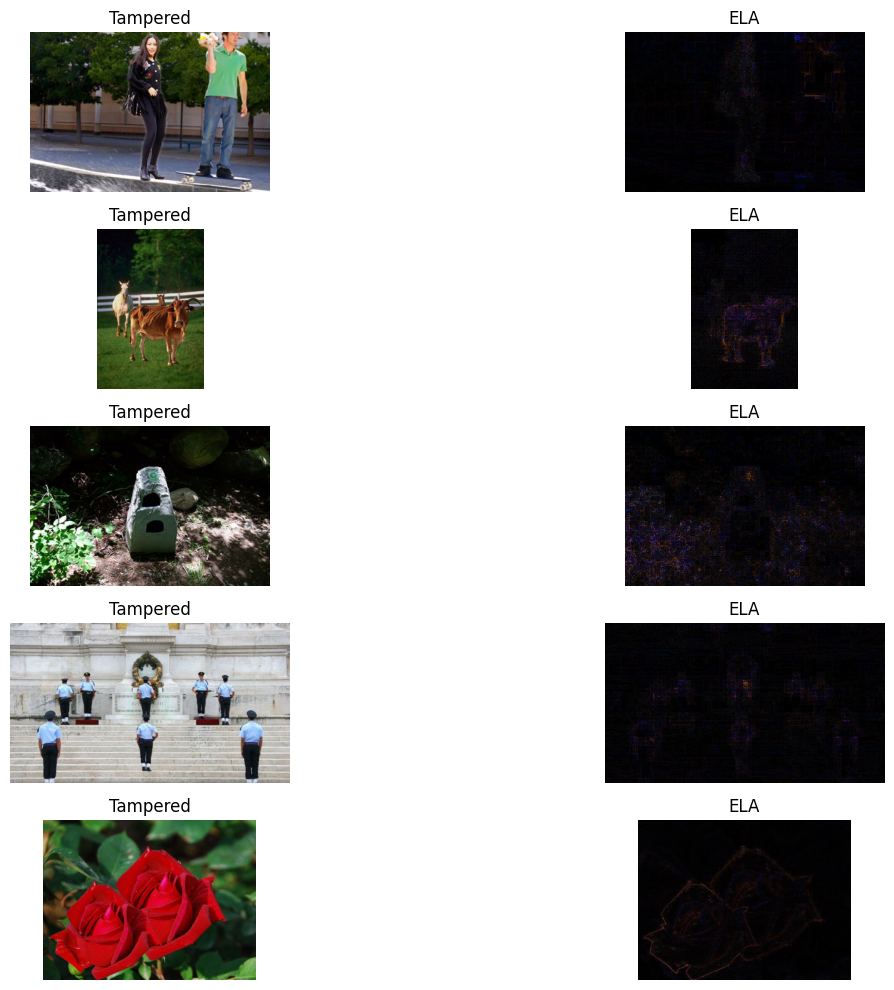

In [ ]:
tp_folder = "/content/CASIA/CASIA2/Tp"

tp_images = random.sample(os.listdir(tp_folder), 5)

plt.figure(figsize=(15,10))

for i, img_name in enumerate(tp_images):

    img_path = os.path.join(tp_folder, img_name)

    original = Image.open(img_path)
    ela = convert_to_ela(img_path)

    plt.subplot(5,2,2*i+1)
    plt.imshow(original)
    plt.title("Tampered")
    plt.axis("off")

    plt.subplot(5,2,2*i+2)
    plt.imshow(ela)
    plt.title("ELA")
    plt.axis("off")

plt.tight_layout()
plt.show()

VARIFICATION

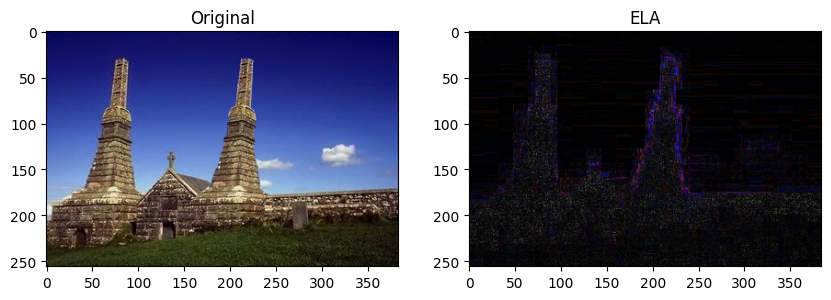

In [ ]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(Image.open(sample_path))
plt.title("Original")

plt.subplot(1,2,2)
plt.imshow(ela_image)
plt.title("ELA")

plt.show()

Compare Tampered Image + Ground Truth Mask + ELA

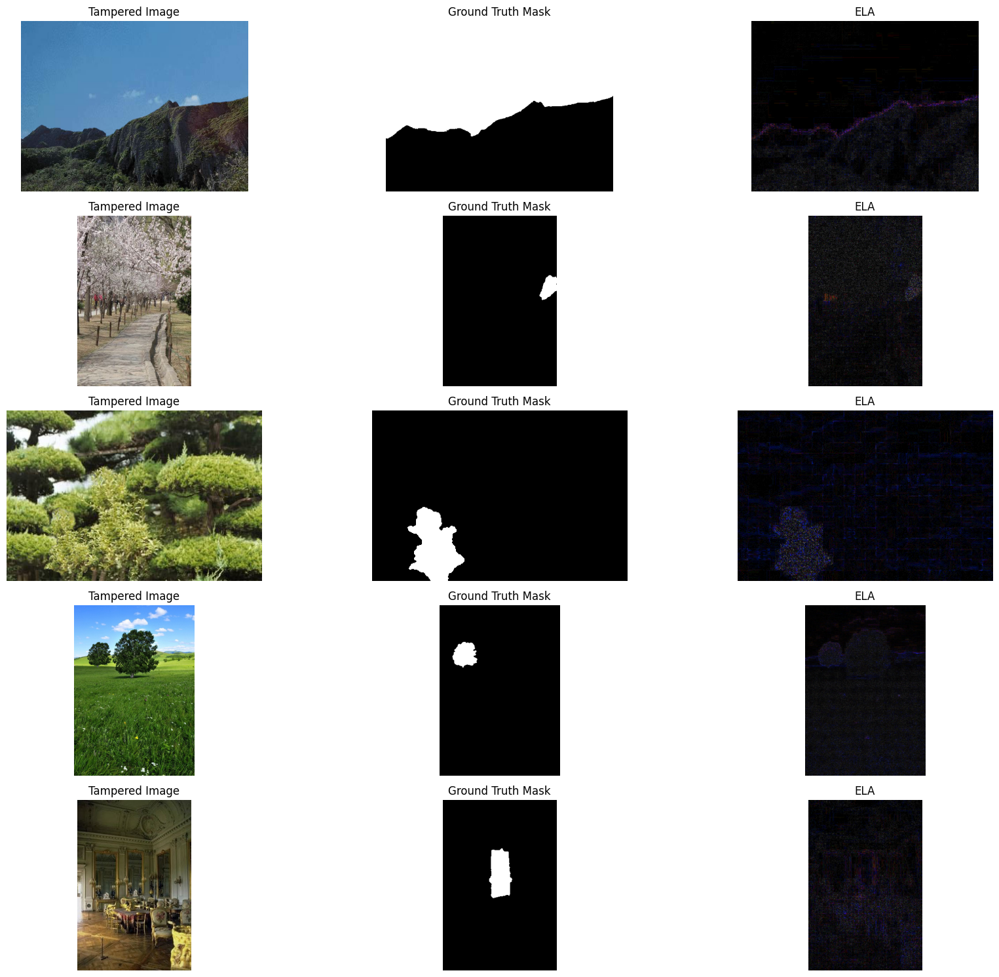

In [ ]:
tp_folder = "/content/CASIA/CASIA2/Tp"
gt_folder = "/content/CASIA/CASIA2/CASIA 2 Groundtruth"

tp_images = random.sample(os.listdir(tp_folder), 5)

plt.figure(figsize=(18,15))

row = 1

for img_name in tp_images:

    gt_name = os.path.splitext(img_name)[0] + "_gt.png"

    gt_path = os.path.join(gt_folder, gt_name)

    if not os.path.exists(gt_path):
        continue

    img_path = os.path.join(tp_folder, img_name)

    original = Image.open(img_path)
    mask = Image.open(gt_path)
    ela = convert_to_ela(img_path)

    plt.subplot(5,3,(row-1)*3+1)
    plt.imshow(original)
    plt.title("Tampered Image")
    plt.axis("off")

    plt.subplot(5,3,(row-1)*3+2)
    plt.imshow(mask, cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(5,3,(row-1)*3+3)
    plt.imshow(ela)
    plt.title("ELA")
    plt.axis("off")

    row += 1

    if row > 5:
        break

plt.tight_layout()
plt.show()

CHECKING PIXEL STATISTICS

In [ ]:
import numpy as np

ela_array = np.array(ela_image)

print("Min:", ela_array.min())
print("Max:", ela_array.max())
print("Mean:", ela_array.mean())

Min: 0
Max: 255
Mean: 8.98699951171875


In [ ]:
print(ela_image.size)
print(type(ela_image))

(384, 256)
<class 'PIL.Image.Image'>


BUILD DATASET

In [ ]:
import numpy as np
from tqdm import tqdm

X = []
y = []

IMAGE_SIZE = 128

# -------------------------
# Authentic Images (Label 0)
# -------------------------

authentic_files = os.listdir(AU_PATH)[:999]

for file in tqdm(authentic_files):

    try:
        path = os.path.join(AU_PATH, file)

        ela = convert_to_ela_image(path)

        ela = ela.resize((IMAGE_SIZE, IMAGE_SIZE))

        ela = np.array(ela) / 255.0

        X.append(ela)
        y.append(0)

    except Exception as e:
        pass


# -------------------------
# Tampered Images (Label 1)
# -------------------------

tampered_files = os.listdir(TP_PATH)[:999]

for file in tqdm(tampered_files):

    try:
        path = os.path.join(TP_PATH, file)

        ela = convert_to_ela_image(path)

        ela = ela.resize((IMAGE_SIZE, IMAGE_SIZE))

        ela = np.array(ela) / 255.0

        X.append(ela)
        y.append(1)

    except Exception as e:
        pass

100%|██████████| 999/999 [00:15<00:00, 66.25it/s]


In [ ]:
import os
import random
import numpy as np

from PIL import Image, ImageChops, ImageEnhance
from tqdm import tqdm

# Paths
AU_FOLDER = "/content/CASIA/CASIA2/Au"
TP_FOLDER = "/content/CASIA/CASIA2/Tp"

IMG_SIZE = 128
SAMPLES_PER_CLASS = 1000

In [ ]:
def convert_to_ela(image_path, quality=90):

    temp_filename = "temp.jpg"

    image = Image.open(image_path).convert("RGB")

    image.save(temp_filename, "JPEG", quality=quality)

    compressed = Image.open(temp_filename)

    ela_image = ImageChops.difference(image, compressed)

    extrema = ela_image.getextrema()

    max_diff = max([ex[1] for ex in extrema])

    if max_diff == 0:
        max_diff = 1

    scale = 255.0 / max_diff

    ela_image = ImageEnhance.Brightness(ela_image).enhance(scale)

    return ela_image

In [ ]:
X = []
y = []

Load Authentic Images (Label = 0)

In [ ]:
au_images = random.sample(os.listdir(AU_FOLDER), SAMPLES_PER_CLASS)

for img_name in tqdm(au_images):

    try:
        img_path = os.path.join(AU_FOLDER, img_name)

        ela = convert_to_ela(img_path)

        ela = ela.resize((IMG_SIZE, IMG_SIZE))

        ela = np.array(ela) / 255.0

        X.append(ela)
        y.append(0)

    except:
        continue

100%|██████████| 1000/1000 [00:09<00:00, 104.94it/s]


Load Tampered Images (Label = 1)

In [ ]:
tp_images = random.sample(os.listdir(TP_FOLDER), SAMPLES_PER_CLASS)

for img_name in tqdm(tp_images):

    try:
        img_path = os.path.join(TP_FOLDER, img_name)

        ela = convert_to_ela(img_path)

        ela = ela.resize((IMG_SIZE, IMG_SIZE))

        ela = np.array(ela) / 255.0

        X.append(ela)
        y.append(1)

    except:
        continue

100%|██████████| 1000/1000 [00:15<00:00, 66.13it/s]


In [ ]:
X = np.array(X, dtype=np.float32)
y = np.array(y)

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nAuthentic Images:", np.sum(y == 0))
print("Tampered Images:", np.sum(y == 1))

X shape: (3998, 128, 128, 3)
y shape: (3998,)

Authentic Images: 1999
Tampered Images: 1999


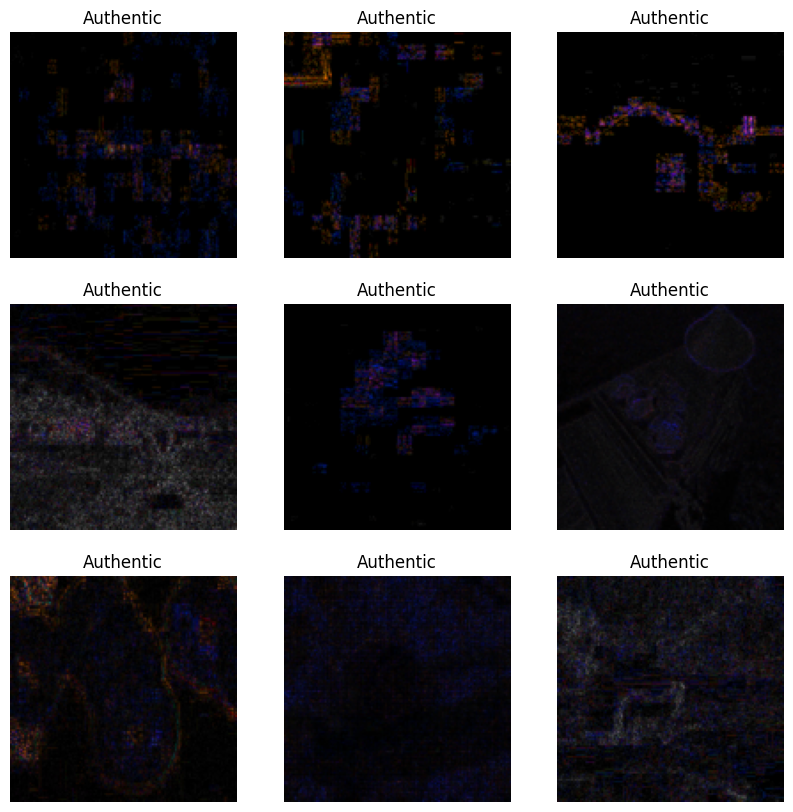

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))

for i in range(9):

    plt.subplot(3,3,i+1)

    plt.imshow(X[i])

    plt.title("Authentic" if y[i] == 0 else "Tampered")

    plt.axis("off")

plt.show()

In [ ]:
print(X.shape)
print(y.shape)

(3998, 128, 128, 3)
(3998,)


Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (3198, 128, 128, 3)
Testing Set: (800, 128, 128, 3)


In [ ]:
print("Training Authentic:", sum(y_train == 0))
print("Training Tampered:", sum(y_train == 1))

print("Testing Authentic:", sum(y_test == 0))
print("Testing Tampered:", sum(y_test == 1))

Training Authentic: 1599
Training Tampered: 1599
Testing Authentic: 400
Testing Tampered: 400


In [ ]:
print(X_train.shape)
print(X_test.shape)

(3198, 128, 128, 3)
(800, 128, 128, 3)


Build the CNN

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential()

# Convolution Block 1
model.add(
    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(128,128,3)
    )
)

model.add(MaxPooling2D((2,2)))

# Convolution Block 2
model.add(
    Conv2D(
        64,
        (3,3),
        activation='relu'
    )
)

model.add(MaxPooling2D((2,2)))

# Convolution Block 3
model.add(
    Conv2D(
        128,
        (3,3),
        activation='relu'
    )
)

model.add(MaxPooling2D((2,2)))

# Classifier
model.add(Flatten())

model.add(Dense(128, activation='relu'))

model.add(Dropout(0.5))

model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Compile the CNN

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


training

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=32
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 64s 624ms/step - accuracy: 0.7708 - loss: 0.4603 - val_accuracy: 0.8438 - val_loss: 0.3906
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 61s 611ms/step - accuracy: 0.8680 - loss: 0.3560 - val_accuracy: 0.8487 - val_loss: 0.3815
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 82s 610ms/step - accuracy: 0.8768 - loss: 0.3372 - val_accuracy: 0.8037 - val_loss: 0.4640
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 61s 609ms/step - accuracy: 0.8818 - loss: 0.3246 - val_accuracy: 0.8425 - val_loss: 0.3879
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 60s 600ms/step - accuracy: 0.8768 - loss: 0.3217 - val_accuracy: 0.8475 - val_loss: 0.3761
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 83s 607ms/step - accuracy: 0.8812 - loss: 0.3119 - val_accuracy: 0.8325 - val_loss: 0.4161
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 80s 585ms/step - accuracy: 0.8881 - loss: 0.3064 - val_accuracy: 0.8537 - val_loss: 0.4026
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 83s 595ms/step - accuracy: 0.8937 - loss: 0

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy)

25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 190ms/step - accuracy: 0.8575 - loss: 0.3943
Test Accuracy: 0.8575000166893005


confusion matrix

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5).astype(int)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 243ms/step
[[333  67]
 [ 52 348]]
              precision    recall  f1-score   support

           0       0.86      0.83      0.85       400
           1       0.84      0.87      0.85       400

    accuracy                           0.85       800
   macro avg       0.85      0.85      0.85       800
weighted avg       0.85      0.85      0.85       800



In [ ]:
for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__)

0 conv2d_3 Conv2D
1 max_pooling2d_3 MaxPooling2D
2 conv2d_4 Conv2D
3 max_pooling2d_4 MaxPooling2D
4 conv2d_5 Conv2D
5 max_pooling2d_5 MaxPooling2D
6 flatten_1 Flatten
7 dense_2 Dense
8 dropout_1 Dropout
9 dense_3 Dense


In [ ]:
tampered_indices = np.where(y_test == 1)[0]

idx = tampered_indices[0]

sample = X_test[idx]

prediction = model.predict(
    np.expand_dims(sample, axis=0)
)

print("Prediction Score:", prediction[0][0])
print("Actual Label:", y_test[idx])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
Prediction Score: 0.80451804
Actual Label: 1


In [ ]:
print(type(model))
print(model.built)

<class 'keras.src.models.sequential.Sequential'>
True


In [ ]:
model.predict(X_test[:1])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


array([[0.9538522]], dtype=float32)

In [ ]:
print(model.inputs)
print(model.outputs)

[<KerasTensor shape=(None, 128, 128, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_56>]
[<KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=keras_tensor_111>]


Where exactly did the CNN look when it decided this image was tampered?"

Create the Grad-CAM Function

In [ ]:
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.outputs[0]
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img_array)

        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap /= (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy()

In [ ]:
sample_input = np.expand_dims(
    sample,
    axis=0
)

heatmap = make_gradcam_heatmap(
    sample_input,
    model,
    "last_conv"
)

print("Heatmap Shape:", heatmap.shape)

Heatmap Shape: (28, 28)


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_123']
Received: inputs=Tensor(shape=(1, 128, 128, 3))
  warnings.warn(msg)


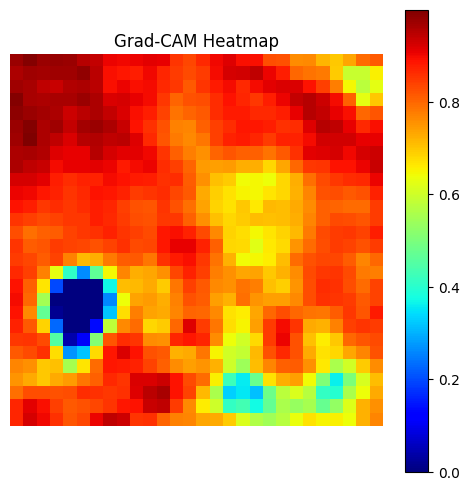

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.imshow(
    heatmap,
    cmap="jet"
)

plt.colorbar()

plt.title("Grad-CAM Heatmap")

plt.axis("off")

plt.show()

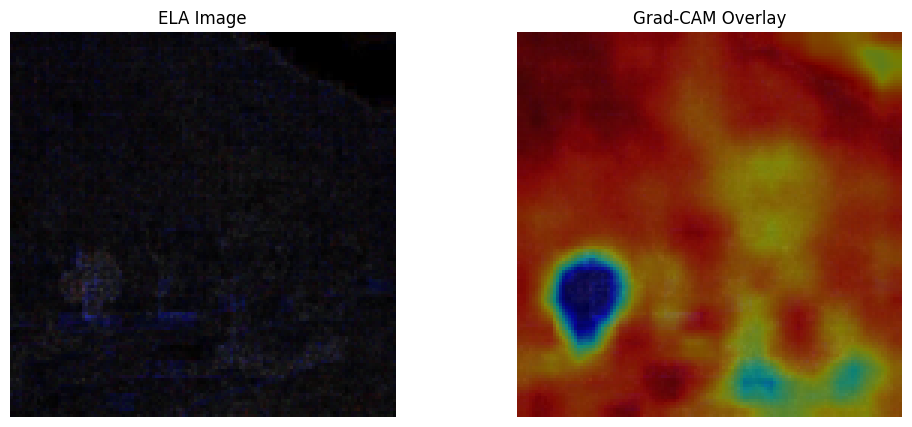

In [ ]:
import cv2
import matplotlib.pyplot as plt

heatmap_resized = cv2.resize(
    heatmap,
    (128, 128)
)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(sample)
plt.title("ELA Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(sample)
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.5
)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.show()

Compare Grad-CAM with Ground Truth Masks

In [ ]:
print(tp_images[0])  # or print the filename of your selected image

Tp_S_NNN_S_N_nat10117_nat10117_11342.jpg


In [ ]:
print(sample_file)

Tp_S_NNN_M_N_arc00094_arc00094_10720.jpg


In [ ]:
import os

for root, dirs, files in os.walk("/content/CASIA"):
    if len(files) > 0:
        print(root)
        print("Sample files:", files[:3])
        print("-"*50)

/content/CASIA/CASIA2/CASIA 2 Groundtruth
Sample files: ['Tp_S_NNN_S_N_nat20025_nat20025_01529_gt.png', 'Tp_S_NNN_S_N_cha10172_cha10172_12284_gt.png', 'Tp_D_NNN_M_B_sec00036_nat00035_20123_gt.png']
--------------------------------------------------
/content/CASIA/CASIA2/Tp
Sample files: ['Tp_S_CNN_S_N_art00080_art00080_01247.tif', 'Tp_S_NRN_S_B_art00039_art00039_01415.tif', 'Tp_D_NRN_M_B_nat10128_nat00097_11542.jpg']
--------------------------------------------------
/content/CASIA/CASIA2/Au
Sample files: ['Au_ind_30036.jpg', 'Au_cha_30560.jpg', 'Au_cha_30636.jpg']
--------------------------------------------------


In [ ]:
print(sample_file)

Tp_S_NNN_M_N_arc00094_arc00094_10720.jpg


In [ ]:
import os

for root, dirs, files in os.walk("/content/CASIA"):
    for file in files:
        if "arc00094" in file:
            print(os.path.join(root, file))

/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_S_NNN_S_N_arc00094_arc00094_01036_gt.png
/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_D_NRN_M_B_arc00094_nat00097_11203_gt.png
/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_D_NRN_S_B_arc00094_ani00100_00314_gt.png
/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_S_NNN_S_B_arc00094_arc00094_01043_gt.png
/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_S_NNN_M_N_arc00094_arc00094_10720_gt.png
/content/CASIA/CASIA2/Tp/Tp_S_NNN_S_N_arc00094_arc00094_01036.tif
/content/CASIA/CASIA2/Tp/Tp_D_NRN_S_B_arc00094_ani00100_00314.tif
/content/CASIA/CASIA2/Tp/Tp_S_NNN_M_N_arc00094_arc00094_10720.jpg
/content/CASIA/CASIA2/Tp/Tp_D_NRN_M_B_arc00094_nat00097_11203.jpg
/content/CASIA/CASIA2/Tp/Tp_S_NNN_S_B_arc00094_arc00094_01043.tif


In [ ]:
for root, dirs, files in os.walk("/content/CASIA"):
    for file in files:
        if "arc00094" in file:
            print(os.path.join(root, file))

/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_S_NNN_S_N_arc00094_arc00094_01036_gt.png
/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_D_NRN_M_B_arc00094_nat00097_11203_gt.png
/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_D_NRN_S_B_arc00094_ani00100_00314_gt.png
/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_S_NNN_S_B_arc00094_arc00094_01043_gt.png
/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_S_NNN_M_N_arc00094_arc00094_10720_gt.png
/content/CASIA/CASIA2/Tp/Tp_S_NNN_S_N_arc00094_arc00094_01036.tif
/content/CASIA/CASIA2/Tp/Tp_D_NRN_S_B_arc00094_ani00100_00314.tif
/content/CASIA/CASIA2/Tp/Tp_S_NNN_M_N_arc00094_arc00094_10720.jpg
/content/CASIA/CASIA2/Tp/Tp_D_NRN_M_B_arc00094_nat00097_11203.jpg
/content/CASIA/CASIA2/Tp/Tp_S_NNN_S_B_arc00094_arc00094_01043.tif


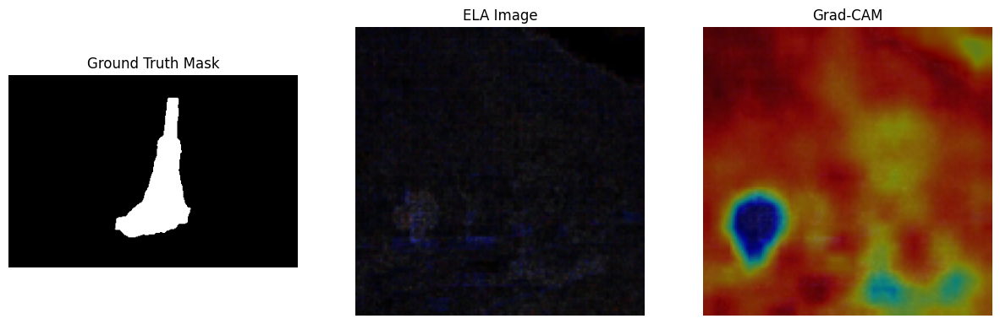

In [ ]:
from PIL import Image
import cv2
import matplotlib.pyplot as plt

mask_path = "/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_S_NNN_M_N_arc00094_arc00094_10720_gt.png"

mask = Image.open(mask_path)

heatmap_resized = cv2.resize(
    heatmap,
    (128,128)
)

plt.figure(figsize=(15,5))

# Ground Truth
plt.subplot(1,3,1)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

# ELA
plt.subplot(1,3,2)
plt.imshow(sample)
plt.title("ELA Image")
plt.axis("off")

# Grad-CAM
plt.subplot(1,3,3)
plt.imshow(sample)
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.5
)
plt.title("Grad-CAM")
plt.axis("off")

plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_123']
Received: inputs=Tensor(shape=(1, 128, 128, 3))
  warnings.warn(msg)


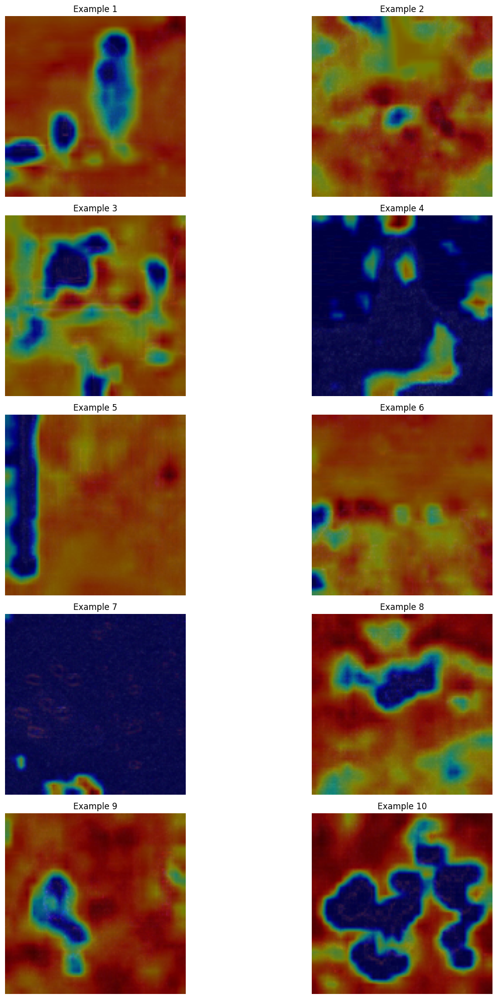

In [ ]:
import random
import cv2
import matplotlib.pyplot as plt
import numpy as np

tampered_indices = np.where(y_test == 1)[0]

selected = random.sample(
    list(tampered_indices),
    10
)

plt.figure(figsize=(15,20))

for i, idx in enumerate(selected):

    sample = X_test[idx]

    heatmap = make_gradcam_heatmap(
        np.expand_dims(sample, axis=0),
        model,
        "last_conv"
    )

    heatmap = cv2.resize(
        heatmap,
        (128,128)
    )

    plt.subplot(5,2,i+1)

    plt.imshow(sample)

    plt.imshow(
        heatmap,
        cmap="jet",
        alpha=0.5
    )

    plt.title(f"Example {i+1}")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

save_dir = "/content/gradcam_results"

os.makedirs(
    save_dir,
    exist_ok=True
)

for i, idx in enumerate(selected):

    sample = X_test[idx]

    heatmap = make_gradcam_heatmap(
        np.expand_dims(sample, axis=0),
        model,
        "last_conv"
    )

    heatmap = cv2.resize(
        heatmap,
        (128,128)
    )

    plt.figure(figsize=(5,5))

    plt.imshow(sample)

    plt.imshow(
        heatmap,
        cmap="jet",
        alpha=0.5
    )

    plt.axis("off")

    plt.savefig(
        f"{save_dir}/gradcam_{i+1}.png",
        bbox_inches="tight",
        dpi=300
    )

    plt.close()

print("All images saved!")

All images saved!


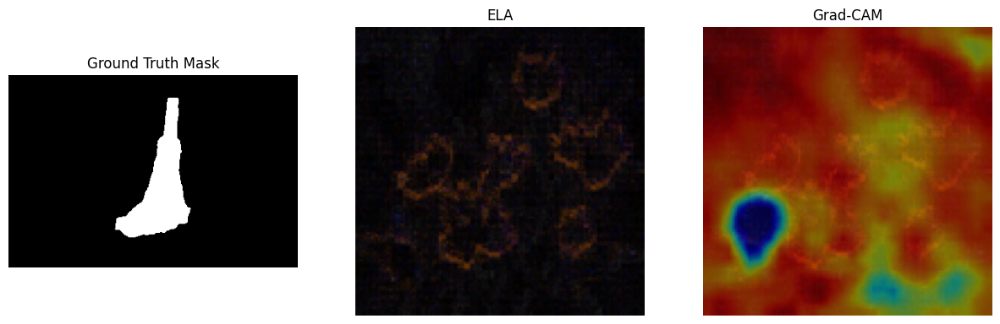

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(sample)
plt.title("ELA")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(sample)
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.5
)
plt.title("Grad-CAM")
plt.axis("off")

plt.savefig(
    "/content/final_gradcam_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**The Ground Truth Mask shows:**

A clear white object (the actual tampered region).

Located roughly in the left-middle area.

**The Grad-CAM shows:**

Very broad attention over almost the entire image.
One strong region in the lower-left.
It doesn't closely match the shape of the mask.








In [ ]:
import os

GT_PATH = "/content/CASIA/CASIA2/CASIA 2 Groundtruth"

mask_files = [
    f for f in os.listdir(GT_PATH)
    if f.endswith(".png")
]

print("Number of masks:", len(mask_files))

Number of masks: 5123


In [ ]:
import os

GT_PATH = "/content/CASIA/CASIA2/CASIA 2 Groundtruth"
TP_PATH = "/content/CASIA/CASIA2/Tp"

print("Masks:", len(os.listdir(GT_PATH)))
print("Tampered Images:", len(os.listdir(TP_PATH)))

Masks: 5123
Tampered Images: 5125


Tp_D_CRN_M_N_nat10154_nat10140_12075_gt.png


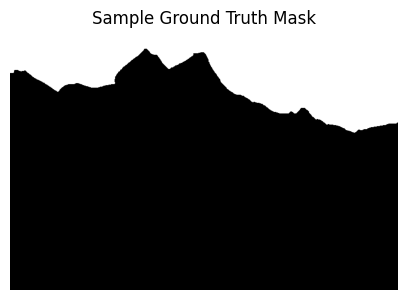

In [ ]:
import random
from PIL import Image
import matplotlib.pyplot as plt

mask_file = random.choice(os.listdir(GT_PATH))

print(mask_file)

mask_path = os.path.join(GT_PATH, mask_file)

mask = Image.open(mask_path)

plt.figure(figsize=(5,5))
plt.imshow(mask, cmap="gray")
plt.title("Sample Ground Truth Mask")
plt.axis("off")
plt.show()

In [ ]:
print(mask.size)

(768, 512)


Build Image-Mask Pairs

In [ ]:
import os

GT_PATH = "/content/CASIA/CASIA2/CASIA 2 Groundtruth"
TP_PATH = "/content/CASIA/CASIA2/Tp"

pairs = []

for mask_name in os.listdir(GT_PATH):

    image_name = mask_name.replace("_gt.png", "")

    jpg_path = os.path.join(
        TP_PATH,
        image_name + ".jpg"
    )

    tif_path = os.path.join(
        TP_PATH,
        image_name + ".tif"
    )

    if os.path.exists(jpg_path):
        pairs.append((jpg_path,
                      os.path.join(GT_PATH, mask_name)))

    elif os.path.exists(tif_path):
        pairs.append((tif_path,
                      os.path.join(GT_PATH, mask_name)))

print("Total Pairs:", len(pairs))

Total Pairs: 4981


In [ ]:
print(pairs[0])

('/content/CASIA/CASIA2/Tp/Tp_S_NNN_S_N_nat20025_nat20025_01529.tif', '/content/CASIA/CASIA2/CASIA 2 Groundtruth/Tp_S_NNN_S_N_nat20025_nat20025_01529_gt.png')


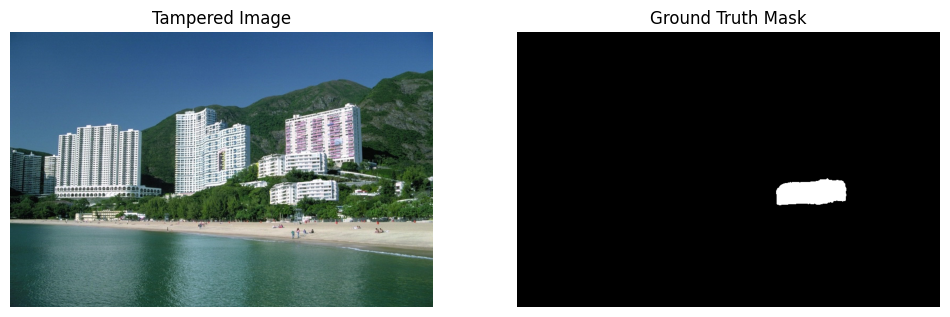

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img_path, mask_path = pairs[0]

img = Image.open(img_path)
mask = Image.open(mask_path)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Tampered Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [ ]:
import numpy as np
from PIL import Image
from tqdm import tqdm

IMG_SIZE = 128
MAX_SAMPLES = 1000

X_seg = []
Y_seg = []

for img_path, mask_path in tqdm(pairs[:MAX_SAMPLES]):

    img = Image.open(img_path).convert("RGB")
    img = img.resize((IMG_SIZE, IMG_SIZE))

    mask = Image.open(mask_path).convert("L")
    mask = mask.resize((IMG_SIZE, IMG_SIZE))

    img = np.array(img) / 255.0

    mask = np.array(mask) / 255.0

    mask = (mask > 0.5).astype(np.float32)

    X_seg.append(img)
    Y_seg.append(mask)

X_seg = np.array(X_seg, dtype=np.float32)

Y_seg = np.array(Y_seg, dtype=np.float32)

Y_seg = np.expand_dims(
    Y_seg,
    axis=-1
)

print("X_seg shape:", X_seg.shape)
print("Y_seg shape:", Y_seg.shape)

100%|██████████| 1000/1000 [00:13<00:00, 72.80it/s]


X_seg shape: (1000, 128, 128, 3)
Y_seg shape: (1000, 128, 128, 1)


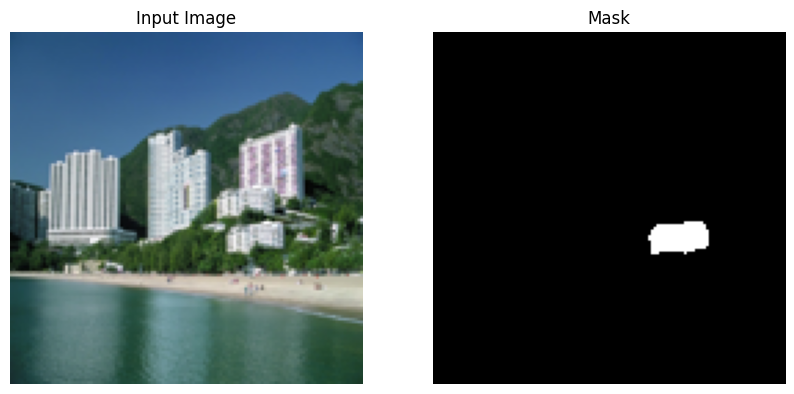

In [ ]:
idx = 0

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(X_seg[idx])
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(
    Y_seg[idx].squeeze(),
    cmap="gray"
)
plt.title("Mask")
plt.axis("off")

plt.show()

Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train_seg, X_test_seg, Y_train_seg, Y_test_seg = train_test_split(
    X_seg,
    Y_seg,
    test_size=0.2,
    random_state=42
)

print(X_train_seg.shape)
print(X_test_seg.shape)

print(Y_train_seg.shape)
print(Y_test_seg.shape)

(800, 128, 128, 3)
(200, 128, 128, 3)
(800, 128, 128, 1)
(200, 128, 128, 1)


In [ ]:
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

inputs = Input((128,128,3))

# Encoder
c1 = Conv2D(16, 3, activation='relu', padding='same')(inputs)
c1 = Conv2D(16, 3, activation='relu', padding='same')(c1)
p1 = MaxPooling2D()(c1)

c2 = Conv2D(32, 3, activation='relu', padding='same')(p1)
c2 = Conv2D(32, 3, activation='relu', padding='same')(c2)
p2 = MaxPooling2D()(c2)

c3 = Conv2D(64, 3, activation='relu', padding='same')(p2)
c3 = Conv2D(64, 3, activation='relu', padding='same')(c3)
p3 = MaxPooling2D()(c3)

# Bottleneck
bn = Conv2D(128, 3, activation='relu', padding='same')(p3)
bn = Conv2D(128, 3, activation='relu', padding='same')(bn)

# Decoder
u1 = UpSampling2D()(bn)
u1 = concatenate([u1, c3])

c4 = Conv2D(64, 3, activation='relu', padding='same')(u1)
c4 = Conv2D(64, 3, activation='relu', padding='same')(c4)

u2 = UpSampling2D()(c4)
u2 = concatenate([u2, c2])

c5 = Conv2D(32, 3, activation='relu', padding='same')(u2)
c5 = Conv2D(32, 3, activation='relu', padding='same')(c5)

u3 = UpSampling2D()(c5)
u3 = concatenate([u3, c1])

c6 = Conv2D(16, 3, activation='relu', padding='same')(u3)
c6 = Conv2D(16, 3, activation='relu', padding='same')(c6)

outputs = Conv2D(
    1,
    1,
    activation='sigmoid'
)(c6)

unet = Model(inputs, outputs)

unet.summary()

Model: "functional_45"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 128, 128,  │        448 │ input_layer_4[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 128, 128,  │      2,320 │ conv2d_10[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_12    │ (None, 64, 64,    │          0 │ conv2d_11[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 64,    │      4,640 │ max_pooling2d_12… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 64, 64,    │      9,248 │ conv2d_12[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_13    │ (None, 32, 32,    │          0 │ conv2d_13[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 32, 32,    │     18,496 │ max_pooling2d_13… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_14[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_14    │ (None, 16, 16,    │          0 │ conv2d_15[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 16, 16,    │     73,856 │ max_pooling2d_14… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 16, 16,    │    147,584 │ conv2d_16[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_17[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_15[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 32, 32,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_18[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 64, 64,    │          0 │ conv2d_19[0][0] 

 Total params: 487,297 (1.86 MB)

 Trainable params: 487,297 (1.86 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
unet.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("U-Net compiled successfully!")

U-Net compiled successfully!


In [ ]:
history_seg = unet.fit(
    X_train_seg,
    Y_train_seg,
    validation_data=(
        X_test_seg,
        Y_test_seg
    ),
    epochs=5,
    batch_size=8
)

Epoch 1/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 87s 821ms/step - accuracy: 0.8955 - loss: 0.3672 - val_accuracy: 0.9020 - val_loss: 0.3432
Epoch 2/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 81s 807ms/step - accuracy: 0.9096 - loss: 0.3109 - val_accuracy: 0.9020 - val_loss: 0.3183
Epoch 3/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 81s 801ms/step - accuracy: 0.9096 - loss: 0.3143 - val_accuracy: 0.9020 - val_loss: 0.3288
Epoch 4/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 82s 801ms/step - accuracy: 0.9096 - loss: 0.3018 - val_accuracy: 0.9020 - val_loss: 0.3173
Epoch 5/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 83s 806ms/step - accuracy: 0.9096 - loss: 0.3004 - val_accuracy: 0.9020 - val_loss: 0.3093


Split Segmentation Dataset

In [ ]:
from sklearn.model_selection import train_test_split

X_train_seg, X_test_seg, Y_train_seg, Y_test_seg = train_test_split(
    X_seg,
    Y_seg,
    test_size=0.2,
    random_state=42
)

print(X_train_seg.shape)
print(X_test_seg.shape)

print(Y_train_seg.shape)
print(Y_test_seg.shape)

(800, 128, 128, 3)
(200, 128, 128, 3)
(800, 128, 128, 1)
(200, 128, 128, 1)


Build U-Net

In [ ]:
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

inputs = Input(shape=(128,128,3))

# Encoder

c1 = Conv2D(16,3,activation='relu',padding='same')(inputs)
c1 = Conv2D(16,3,activation='relu',padding='same')(c1)
p1 = MaxPooling2D()(c1)

c2 = Conv2D(32,3,activation='relu',padding='same')(p1)
c2 = Conv2D(32,3,activation='relu',padding='same')(c2)
p2 = MaxPooling2D()(c2)

c3 = Conv2D(64,3,activation='relu',padding='same')(p2)
c3 = Conv2D(64,3,activation='relu',padding='same')(c3)
p3 = MaxPooling2D()(c3)

# Bottleneck

bn = Conv2D(128,3,activation='relu',padding='same')(p3)
bn = Conv2D(128,3,activation='relu',padding='same')(bn)

# Decoder

u1 = UpSampling2D()(bn)
u1 = concatenate([u1,c3])

c4 = Conv2D(64,3,activation='relu',padding='same')(u1)
c4 = Conv2D(64,3,activation='relu',padding='same')(c4)

u2 = UpSampling2D()(c4)
u2 = concatenate([u2,c2])

c5 = Conv2D(32,3,activation='relu',padding='same')(u2)
c5 = Conv2D(32,3,activation='relu',padding='same')(c5)

u3 = UpSampling2D()(c5)
u3 = concatenate([u3,c1])

c6 = Conv2D(16,3,activation='relu',padding='same')(u3)
c6 = Conv2D(16,3,activation='relu',padding='same')(c6)

outputs = Conv2D(
    1,
    1,
    activation='sigmoid'
)(c6)

unet = Model(inputs, outputs)

unet.summary()

Model: "functional_46"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 128, 128,  │        448 │ input_layer_5[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 128, 128,  │      2,320 │ conv2d_25[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_15    │ (None, 64, 64,    │          0 │ conv2d_26[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 64, 64,    │      4,640 │ max_pooling2d_15… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 64, 64,    │      9,248 │ conv2d_27[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_16    │ (None, 32, 32,    │          0 │ conv2d_28[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 32, 32,    │     18,496 │ max_pooling2d_16… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_29[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_17    │ (None, 16, 16,    │          0 │ conv2d_30[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 16, 16,    │     73,856 │ max_pooling2d_17… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 16, 16,    │    147,584 │ conv2d_31[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 32, 32,    │          0 │ conv2d_32[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 32, 32,    │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 192)              │            │ conv2d_30[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 32, 32,    │    110,656 │ concatenate_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_33[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_4     │ (None, 64, 64,    │          0 │ conv2d_34[0][0] 

 Total params: 487,297 (1.86 MB)

 Trainable params: 487,297 (1.86 MB)

 Non-trainable params: 0 (0.00 B)

compile

In [ ]:
unet.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("U-Net Compiled Successfully")

U-Net Compiled Successfully


Train

Start with 5 epochs.